# Анализ лояльности пользователей Яндекс Афиши

## Этапы выполнения проекта

### 1. Загрузка данных и их предобработка

---

**Задача 1.1:** Напишите SQL-запрос, выгружающий в датафрейм pandas необходимые данные. Используйте следующие параметры для подключения к базе данных `data-analyst-afisha`:

- **Хост** — `rc1e-oa2gp4mf9egcsq5k.mdb.yandexcloud.net`
- **База данных** — `data-analyst-afisha`
- **Порт** — `6432`
- **Аутентификация** — `Database Native`
- **Пользователь** — `praktikum_student`
- **Пароль** — `Sdf4$2;d-d30pp`

Для выгрузки используйте запрос из предыдущего урока и библиотеку SQLAlchemy.

Выгрузка из базы данных SQL должна позволить собрать следующие данные:

- `user_id` — уникальный идентификатор пользователя, совершившего заказ;
- `device_type_canonical` — тип устройства, с которого был оформлен заказ (`mobile` — мобильные устройства, `desktop` — стационарные);
- `order_id` — уникальный идентификатор заказа;
- `order_dt` — дата создания заказа (используйте данные `created_dt_msk`);
- `order_ts` — дата и время создания заказа (используйте данные `created_ts_msk`);
- `currency_code` — валюта оплаты;
- `revenue` — выручка от заказа;
- `tickets_count` — количество купленных билетов;
- `days_since_prev` — количество дней от предыдущей покупки пользователя, для пользователей с одной покупкой — значение пропущено;
- `event_id` — уникальный идентификатор мероприятия;
- `service_name` — название билетного оператора;
- `event_type_main` — основной тип мероприятия (театральная постановка, концерт и так далее);
- `region_name` — название региона, в котором прошло мероприятие;
- `city_name` — название города, в котором прошло мероприятие.

---


1. Загрузка данных.
Начнём с загрузки библиотек. Будем использовать pandas и библиотеки визуализации данных matplotlib и seaborn, а также phik для построения матрицы корреляции. Для подключения к базе данных загрузим библиотеку SQLAlchemy 

In [111]:
# Для подключения к базе данных импортируем библиотку sqlalchemy, установим модуль psycopg2 и функцию create_engine():
!pip install sqlalchemy
!pip install psycopg2-binary
from sqlalchemy import create_engine

# Импортируем библиотеки
import pandas as pd
import numpy as np

# Загружаем библиотеки для визуализации данных
import matplotlib.pyplot as plt
import seaborn as sns

# Установим библиотеку phik
!pip install phik

# Загружаем библиотеку для расчёта коэффициента корреляции phi_k
from phik import phik_matrix

In [119]:
# Создаём объект, который содержит все данные для подключения к базе данных.

db_config = {'user': 'praktikum_student', # имя пользователя
             'pwd': 'Sdf4$2;d-d30pp', # пароль
             'host': 'rc1e-oa2gp4mf9egcsq5k.mdb.yandexcloud.net',
             'port': 6432, # порт подключения
             'db': 'data-analyst-afisha' # название базы данных
             }

In [120]:
# Создаём строку подключения к базе данных

connection_string = 'postgresql://{}:{}@{}:{}/{}'.format(
    db_config['user'],
    db_config['pwd'],
    db_config['host'],
    db_config['port'],
    db_config['db'],
)

In [121]:
# Для создания соединения передаём строку подключения в функцию create_engine()

engine = create_engine(connection_string)

In [122]:
# Извлекаем результат. Запрос запишем в переменную table_for_analize

table_for_analyze = '''
SELECT user_id, device_type_canonical, order_id, created_dt_msk AS order_dt, created_ts_msk AS order_ts, currency_code, revenue, tickets_count, (created_dt_msk::date - LAG (created_dt_msk::date, 1, null) OVER (PARTITION BY user_id ORDER BY created_dt_msk)) AS days_since_prev, p.event_id, e.event_name_code AS event_name, e.event_type_main, service_name, region_name, city_name
FROM afisha.purchases p
INNER JOIN afisha.events e ON p.event_id = e.event_id
JOIN afisha.city c ON e.city_id = c.city_id
JOIN afisha.regions r ON c.region_id = r.region_id
WHERE device_type_canonical in ('mobile', 'desktop') AND e.event_type_main != 'фильм'
ORDER BY user_id
'''

In [123]:
# Результат выдачи SQL-запроса записывем в датафрейм с помощью метода pd.read_sql_query():

df = pd.read_sql_query(table_for_analyze, con=engine)

---

**Задача 1.2:** Изучите общую информацию о выгруженных данных. Оцените корректность выгрузки и объём полученных данных.

Предположите, какие шаги необходимо сделать на стадии предобработки данных — например, скорректировать типы данных.

Зафиксируйте основную информацию о данных в кратком промежуточном выводе.

---

Познакомимся с данными датасета — выведем первые строки методом head(), а информацию о датафрейме методом info():

In [124]:
df.head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк


In [125]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 15 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

Датасет содержит 15 столбцов и 290611 строк, в которых представлена информация об использовании клиентами сервиса "Яндекс Афиша".

После первичного анализа данных можно сделать следующие выводы:
- Названия столбцов в формате snake case, что будет способствовать дальнейшему анализу.
- Все представленные числовые значения хранятся в типах данных `int64` или `float64`. Значения в столбцах `tickets_count` и `days_since_prev`  представлены целыми числами. Так как столбец `days_since_prev` содежит строки с `Nan`, то тип данных `float64` является подходящим.
- Пропуски содержатся только в столбце `days_since_prev`.
- Все столбцы, содержащие строковые значения представлены в подходящем типе данных `object`.
- Судя по первому знакомству с данными, значения в столбцах соответствуют своему описанию.
- Общий объём памяти датафрейма немногим более 33 MB.


---

###  2. Предобработка данных

Выполните все стандартные действия по предобработке данных:

---

**Задача 2.1:** Данные о выручке сервиса представлены в российских рублях и казахстанских тенге. Приведите выручку к единой валюте — российскому рублю.

Для этого используйте датасет с информацией о курсе казахстанского тенге по отношению к российскому рублю за 2024 год — `final_tickets_tenge_df.csv`. Его можно загрузить по пути `https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')`

Значения в рублях представлено для 100 тенге.

Результаты преобразования сохраните в новый столбец `revenue_rub`.

---


In [126]:
# Выгружаем данные о курсе казахстанского тенге к рублю переменную exchange_df
exchange_df = pd.read_csv('https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv')

In [128]:
# ознакомимся с датасетом
exchange_df.head()

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


In [131]:
# Проверим тип данных датасета с курсами валют
exchange_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   data     357 non-null    datetime64[ns]
 1   nominal  357 non-null    int64         
 2   curs     357 non-null    float64       
 3   cdx      357 non-null    object        
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 11.3+ KB


In [132]:
# Видим что дата предсталена типом данных object. Переводим в тип данных datatime

exchange_df['data'] = pd.to_datetime(exchange_df['data']) 

In [134]:
# объеденим датафрейм с курсами тенге exchange_df с основным датасетом df по столбцам с датой и валютой

df_merged = df.merge(exchange_df, left_on=['order_dt', 'currency_code'], right_on=['data', 'cdx'], how='left')


In [148]:
# Создаём новый столбец, где все ценники приведены к рублям.

df_merged['revenue_rub'] =np.where(
        df_merged['curs'].isna(), 
        df_merged['revenue'],  # если курс NaN, берём сумму как есть
        df_merged['revenue'] * df_merged['curs'] / 100)

# Округляем полученный столбец до сотых долей

df_merged['revenue_rub'] = df_merged['revenue_rub'].round(2) 

In [149]:
# Удаляем ненужные столбцы, полученные после объединения датасетов

cols_to_drop = ['data', 'nominal', 'curs', 'cdx'] 
df_clean = df_merged.drop(columns=cols_to_drop)

In [150]:
# Выведем первые строки обновленного датасета
df_clean.head()

,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,event_name,event_type_main,service_name,region_name,city_name,revenue_rub
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Край билетов,Каменевский регион,Глиногорск,1521.94
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Мой билет,Каменевский регион,Глиногорск,289.45
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,За билетом!,Каменевский регион,Глиногорск,1258.57
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Лови билет!,Североярская область,Озёрск,8.49
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Билеты без проблем,Озернинский край,Родниковецк,1390.41


---

**Задача 2.2:**

- Проверьте данные на пропущенные значения. Если выгрузка из SQL была успешной, то пропуски должны быть только в столбце `days_since_prev`.
- Преобразуйте типы данных в некоторых столбцах, если это необходимо. Обратите внимание на данные с датой и временем, а также на числовые данные, размерность которых можно сократить.
- Изучите значения в ключевых столбцах. Обработайте ошибки, если обнаружите их.
    - Проверьте, какие категории указаны в столбцах с номинальными данными. Есть ли среди категорий такие, что обозначают пропуски в данных или отсутствие информации? Проведите нормализацию данных, если это необходимо.
    - Проверьте распределение численных данных и наличие в них выбросов. Для этого используйте статистические показатели, гистограммы распределения значений или диаграммы размаха.
        
        Важные показатели в рамках поставленной задачи — это выручка с заказа (`revenue_rub`) и количество билетов в заказе (`tickets_count`), поэтому в первую очередь проверьте данные в этих столбцах.
        
        Если обнаружите выбросы в поле `revenue_rub`, то отфильтруйте значения по 99 перцентилю.

После предобработки проверьте, были ли отфильтрованы данные. Если были, то оцените, в каком объёме. Сформулируйте промежуточный вывод, зафиксировав основные действия и описания новых столбцов.

---

In [151]:
# Применяем метод isna() для выявления пропусков и метод sum() для посчета количества.
df_clean.isna().sum()

user_id                      0
device_type_canonical        0
order_id                     0
order_dt                     0
order_ts                     0
currency_code                0
revenue                      0
tickets_count                0
days_since_prev          21933
event_id                     0
event_name                   0
event_type_main              0
service_name                 0
region_name                  0
city_name                    0
revenue_rub                  0
dtype: int64

In [152]:
# Подсчитываем долю строк с пропусками
df_clean.isna().sum() / df_clean.shape[0]

user_id                  0.000000
device_type_canonical    0.000000
order_id                 0.000000
order_dt                 0.000000
order_ts                 0.000000
currency_code            0.000000
revenue                  0.000000
tickets_count            0.000000
days_since_prev          0.075472
event_id                 0.000000
event_name               0.000000
event_type_main          0.000000
service_name             0.000000
region_name              0.000000
city_name                0.000000
revenue_rub              0.000000
dtype: float64

В датафрейме обнаружено 21933 пропусков в столбце days_since_prev — это 7.5% данных. Доля провусков небольшая.

In [153]:
# Типы данных соответсвуют содержанию столбцов.
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 290611 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  event_name             290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  service_name           290611 non-null  obje

Проверим какие категории указаны в столбцах с номинальными данными. Посмотрим на уникальные значения в столбцах с категориальными данными - среди них код валюты, тип мероприятия, название билетного опетора, регион и город.

In [154]:
# Проверяем уникальные значения в столбцах
for column in ['currency_code', 'event_type_main', 'service_name', 'region_name', 'city_name']:
    print(f'Уникальные значения в столбце {column}:')
    print(df_clean[column].sort_values().unique())
    print()

Уникальные значения в столбце currency_code:
['kzt' 'rub']

Уникальные значения в столбце event_type_main:
['выставки' 'другое' 'концерты' 'спорт' 'стендап' 'театр' 'ёлки']

Уникальные значения в столбце service_name:
['Crazy ticket!' 'Show_ticket' 'Билет по телефону' 'Билеты без проблем'
 'Билеты в интернете' 'Билеты в руки' 'Быстробилет' 'Быстрый кассир'
 'Весь в билетах' 'Восьмёрка' 'Вперёд!' 'Выступления.ру'
 'Городской дом культуры' 'Дом культуры' 'Дырокол' 'За билетом!'
 'Зе Бест!' 'КарандашРУ' 'Кино билет' 'Край билетов' 'Лимоны'
 'Лови билет!' 'Лучшие билеты' 'Мир касс' 'Мой билет' 'Облачко'
 'Прачечная' 'Радио ticket' 'Реестр' 'Росбилет' 'Тебе билет!' 'Телебилет'
 'Тех билет' 'Цвет и билет' 'Шоу начинается!' 'Яблоко']

Уникальные значения в столбце region_name:
['Белоярская область' 'Берестовский округ' 'Берёзовская область'
 'Боровлянский край' 'Верховинская область' 'Верхозёрский край'
 'Верхоречная область' 'Ветренский регион' 'Вишнёвский край'
 'Глиногорская область' 'Голу

Все значения выглядят корректными. Прверим статистику данных в числовых колонках

Проверьте распределение численных данных и наличие в них выбросов. Для этого используйте статистические показатели, гистограммы распределения значений или диаграммы размаха

In [155]:
# проеверим столбец с количеством билетов:
print(df_clean['tickets_count'].value_counts())


3     92247
2     83807
4     54812
1     41798
5     13476
6      4283
7        62
9        38
8        21
10       19
11       13
13        7
17        6
19        5
12        4
14        4
15        2
27        2
30        2
37        1
47        1
57        1
Name: tickets_count, dtype: int64


Возможне есть выбросы, больше всего покупают по 3 билета, есть покупатель с количеством билетов 57 - но можно предположить, что покупатель - учебное заведение (а может быть и перекуп) 

In [156]:
# изучим статистику столбца с количеством купленных билетов

print('Статистические показатели столбца tickets_count:')
df['tickets_count'].describe()

Статистические показатели столбца tickets_count:


count    290611.000000
mean          2.754311
std           1.170620
min           1.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          57.000000
Name: tickets_count, dtype: float64

Среднее и медианное значение близки друг к другу, но разница между минимальным и максимальным значениями довольно большая, что может говорит о выбросах

Дополнительно построим гистограмму распределения значений и диаграмму размаха.

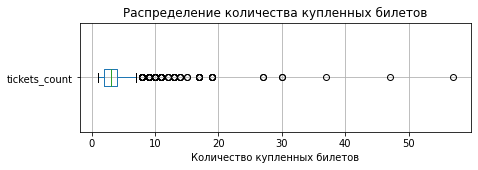

In [157]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 2))

# Строим диаграмму размаха значений в столбце balance
df_clean.boxplot(column='tickets_count', vert=False)

# Добавляем заголовок и метки оси
plt.title('Распределение количества купленных билетов')
plt.xlabel('Количество купленных билетов')

# Выводим график
plt.show()

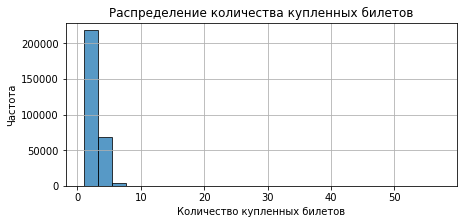

In [158]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 3))

# Строим гистограмму с помощью pandas через plot(kind='hist')
df_clean['tickets_count'].plot(
                kind='hist', # Тип графика - гистограмма
                bins=25, # Устанавливаем количество корзин - всего 25
                alpha=0.75,
                edgecolor='black',
                rot=0, # Градус вращения подписи по оси Х
)

# Настраиваем оформление графика
plt.title('Распределение количества купленных билетов')
plt.xlabel('Количество купленных билетов')
plt.ylabel('Частота')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

Распределение количества купленных билетов сильно скошенное вправо.

In [159]:
# изучим статистику столбеца с выручкой в рублях

print('Статистические показатели столбца revenue_rub:')
df_clean['revenue_rub'].describe()


Статистические показатели столбца revenue_rub:


count    290611.000000
mean        555.571989
std         875.498170
min         -90.760000
25%         113.970000
50%         351.140000
75%         802.050000
max       81174.540000
Name: revenue_rub, dtype: float64

Можно предположить, что данные баланса имеют ненормальное распределение. Об этом говорит разница среднего и медианного значений. К тому же значение стандартного отклонения высокое — 875, при среднем 555 это указывает, что данные могут иметь широкий разброс. Разница между минимальным и максимальным значениями это подтверждает.

Дополнительно проверим это и построим гистограмму распределения значений и диаграмму размаха.

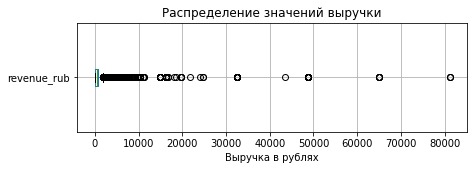

In [160]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 2))

# Строим диаграмму размаха значений в столбце balance
df_clean.boxplot(column='revenue_rub', vert=False)

# Добавляем заголовок и метки оси
plt.title('Распределение значений выручки')
plt.xlabel('Выручка в рублях')

# Выводим график
plt.show()

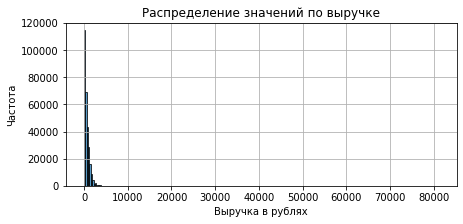

In [161]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 3))

# Строим гистограмму с помощью pandas через plot(kind='hist')
df_clean['revenue_rub'].plot(
                kind='hist', # Тип графика - гистограмма
                bins=250, # Устанавливаем количество корзин - всего 25
                alpha=0.75,
                edgecolor='black',
                rot=0, # Градус вращения подписи по оси Х
)

# Настраиваем оформление графика
plt.title('Распределение значений по выручке')
plt.xlabel('Выручка в рублях')
plt.ylabel('Частота')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

In [162]:
# Ящик с усами и гистограмма указывают, что распределение действительно ненормальное, а так же присутсвуют выбросы.

Отфильтруем столбец выручки в рублях по 99 перцентилю:

In [163]:
limit = df_clean['revenue_rub'].quantile(0.99)
df_filtered = df_clean[df_clean['revenue_rub'] <= limit]


Посчитаем статистику для обновленных дынных с выручкой

In [164]:
# изучим статистику столбеца с выручкой в рублях

print('Статистические показатели столбца revenue_rub:')
df_filtered['revenue_rub'].describe()


Статистические показатели столбца revenue_rub:


count    287786.000000
mean        518.029227
std         511.963781
min         -90.760000
25%         111.850000
50%         343.850000
75%         788.660000
max        2628.420000
Name: revenue_rub, dtype: float64

Построим ящик с усами и гистограмму для обновленного датасета

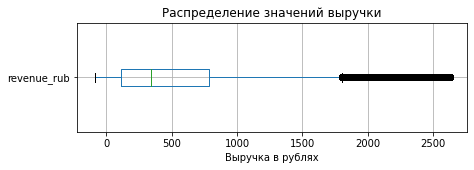

In [165]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 2))

# Строим диаграмму размаха значений в столбце balance
df_filtered.boxplot(column='revenue_rub', vert=False)

# Добавляем заголовок и метки оси
plt.title('Распределение значений выручки')
plt.xlabel('Выручка в рублях')

# Выводим график
plt.show()

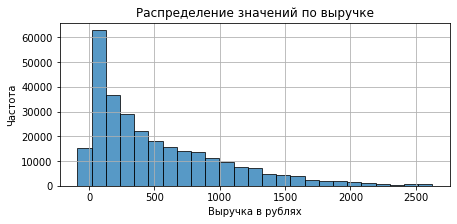

In [166]:
# Создаём контейнер графика matplotlib и задаём его размер
plt.figure(figsize=(7, 3))

# Строим гистограмму с помощью pandas через plot(kind='hist')
df_filtered['revenue_rub'].plot(
                kind='hist', # Тип графика - гистограмма
                bins=25, # Устанавливаем количество корзин - всего 25
                alpha=0.75,
                edgecolor='black',
                rot=0, # Градус вращения подписи по оси Х
)

# Настраиваем оформление графика
plt.title('Распределение значений по выручке')
plt.xlabel('Выручка в рублях')
plt.ylabel('Частота')
# Добавляем сетку графика
plt.grid()

# Выводим график
plt.show()

In [167]:
df_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 287786 entries, 0 to 290610
Data columns (total 16 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                287786 non-null  object        
 1   device_type_canonical  287786 non-null  object        
 2   order_id               287786 non-null  int64         
 3   order_dt               287786 non-null  datetime64[ns]
 4   order_ts               287786 non-null  datetime64[ns]
 5   currency_code          287786 non-null  object        
 6   revenue                287786 non-null  float64       
 7   tickets_count          287786 non-null  int64         
 8   days_since_prev        266060 non-null  float64       
 9   event_id               287786 non-null  int64         
 10  event_name             287786 non-null  object        
 11  event_type_main        287786 non-null  object        
 12  service_name           287786 non-null  obje

Анализ статистики и графических данных показал, что фильтрация по 99 процентилю исключила значительное количество выбросов. Данные стали удобнее для последующего анализа. Разница между максимальным и минимальным значениями стала на много меньше, стандартное отклонение так же уменьшилось.

После фильтрации выбросов в дата сетеосталось 287786 строк (было 290611 - удалили 9.5% данных, считающимися выбросами)

---

### 3. Создание профиля пользователя

В будущем отдел маркетинга планирует создать модель для прогнозирования возврата пользователей. Поэтому сейчас они просят вас построить агрегированные признаки, описывающие поведение и профиль каждого пользователя.

---

**Задача 3.1.** Постройте профиль пользователя — для каждого пользователя найдите:

- дату первого и последнего заказа;
- устройство, с которого был сделан первый заказ;
- регион, в котором был сделан первый заказ;
- билетного партнёра, к которому обращались при первом заказе;
- жанр первого посещённого мероприятия (используйте поле `event_type_main`);
- общее количество заказов;
- средняя выручка с одного заказа в рублях;
- среднее количество билетов в заказе;
- среднее время между заказами.

После этого добавьте два бинарных признака:

- `is_two` — совершил ли пользователь 2 и более заказа;
- `is_five` — совершил ли пользователь 5 и более заказов.

**Рекомендация:** перед тем как строить профиль, отсортируйте данные по времени совершения заказа.

---


В начале отсортируем весь дата сет по времени, так как необходимы данные по первым заказам

In [169]:
# Сортировка по возрастанию времени первой покупки
df_sorted = df_filtered.sort_values('order_dt')

Далее делаем соответсвубщие агрегаци по каждой метрике применяя метод first(). Новый датасет по профилям пользователей назовем 'user_profiles'

In [170]:
# Агрегация
user_profiles = df_sorted.groupby('user_id').agg(
    first_order_date=('order_dt', 'min'),
    last_order_date=('order_dt', 'max'),
    first_device=('device_type_canonical', 'first'),
    first_region=('region_name', 'first'),
    first_service=('service_name', 'first'),
    first_genre=('event_type_main', 'first'),
    orders_count=('order_id', 'nunique'),
    avg_revenue=('revenue_rub', 'mean'),
    avg_tickets=('tickets_count', 'mean')
).reset_index()


Посчитаем среднее время между заказами для каждого пользователя

In [171]:
#Группируем по user_id и считаем среднее время между заказами
avg_gap = (
    df_sorted.sort_values('order_dt')
    .groupby('user_id')['order_dt']
    .diff()                 # разница между текущей и предыдущей датой
    .dt.total_seconds()     # переводим timedelta в секунды
    .groupby(df_clean['user_id'])
    .mean()                 # среднее по группе
    .reset_index(name='avg_time_between_orders_sec')
)

#  Присоединяем к профилю пользователя
user_profiles = user_profiles.merge(avg_gap, on='user_id', how='left')

Добавляем бинарные признаки (совершил ли пользовоатель 2 и более или 5 и более заказов)

In [172]:
user_profiles['is_two'] = (user_profiles['orders_count'] >= 2).astype(int)
user_profiles['is_five'] = (user_profiles['orders_count'] >= 5).astype(int)

In [175]:
# выведем обновленный датасет
user_profiles.head()

,user_id,first_order_date,last_order_date,first_device,first_region,first_service,first_genre,orders_count,avg_revenue,avg_tickets,avg_time_between_orders_sec,is_two,is_five
0,0002849b70a3ce2,2024-08-20,2024-08-20,mobile,Каменевский регион,Край билетов,театр,1,1521.940000,4.000000,NaN,0,0
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,Каменевский регион,Мой билет,выставки,2,774.010000,3.000000,6480000.0,1,0
2,000898990054619,2024-07-13,2024-10-23,mobile,Североярская область,Лови билет!,другое,3,767.213333,2.666667,4406400.0,1,0
3,00096d1f542ab2b,2024-08-15,2024-08-15,desktop,Каменевский регион,Край билетов,театр,1,917.830000,4.000000,NaN,0,0
4,000a55a418c128c,2024-09-29,2024-10-15,mobile,Поленовский край,Лучшие билеты,театр,2,61.310000,1.500000,1382400.0,1,0


---

**Задача 3.2.** Прежде чем проводить исследовательский анализ данных и делать выводы, важно понять, с какими данными вы работаете: насколько они репрезентативны и нет ли в них аномалий.

Используя данные о профилях пользователей, рассчитайте:

- общее число пользователей в выборке;
- среднюю выручку с одного заказа;
- долю пользователей, совершивших 2 и более заказа;
- долю пользователей, совершивших 5 и более заказов.

Также изучите статистические показатели:

- по общему числу заказов;
- по среднему числу билетов в заказе;
- по среднему количеству дней между покупками.

По результатам оцените данные: достаточно ли их по объёму, есть ли аномальные значения в данных о количестве заказов и среднем количестве билетов?

Если вы найдёте аномальные значения, опишите их и примите обоснованное решение о том, как с ними поступить:

- Оставить и учитывать их при анализе?
- Отфильтровать данные по какому-то значению, например, по 95-му или 99-му перцентилю?

Если вы проведёте фильтрацию, то вычислите объём отфильтрованных данных и выведите статистические показатели по обновлённому датасету.

Расчитаем статистики

In [176]:
# Базовые статистики

total_users = len(user_profiles)
avg_rev_per_order = user_profiles['avg_revenue'].mean()
ratio_two = user_profiles['is_two'].mean()
ratio_five = user_profiles['is_five'].mean()


print(f'Всего пользователей: {total_users}, средний чек: {avg_rev_per_order:.2f} рублей, '
      f'доля пользователей с 2+ заказами: {ratio_two:.2%}, '
      f'доля пользователей с 5+ заказами: {ratio_five:.2%}')

# Оценим статистики по количеству заказов, количесву купленных билетов и времени между заказами:

stats = user_profiles[['orders_count', 'avg_tickets', 'avg_time_between_orders_sec']].describe(percentiles=[.95, .99])
print(stats)

Всего пользователей: 21854, средний чек: 544.40 рублей, доля пользователей с 2+ заказами: 61.71%, доля пользователей с 5+ заказами: 29.01%
       orders_count   avg_tickets  avg_time_between_orders_sec
count  21854.000000  21854.000000                 1.348600e+04
mean      13.168573      2.743129                 1.371823e+06
std      121.674800      0.913080                 1.924295e+06
min        1.000000      1.000000                 0.000000e+00
50%        2.000000      2.750000                 6.973714e+05
95%       31.350000      4.000000                 5.313600e+06
99%      152.000000      5.000000                 9.676800e+06
max    10181.000000     11.000000                 1.278720e+07


Анализ статистики выявил выбросы в столбце с количеством заказов, об этом говорит значительнаяразница между максимальным значением и максимальным значением 99-го процентиля. Отфильтруем датасет по 99-му процентилю.

In [177]:
orders_99 = user_profiles['orders_count'].quantile(0.99)
user_profiles_filtered = user_profiles[user_profiles['orders_count'] <= orders_99]

Делаем пересчет статистик для отфильтрованного дата фрейма:

In [178]:
# Базовые статистики

total_users = len(user_profiles_filtered)
avg_rev_per_order = user_profiles_filtered['avg_revenue'].mean()
ratio_two = user_profiles_filtered['is_two'].mean()
ratio_five = user_profiles_filtered['is_five'].mean()


print(f'Всего пользователей: {total_users}, средний чек: {avg_rev_per_order:.2f} рублей, '
      f'доля пользователей с 2+ заказами: {ratio_two:.2%}, '
      f'доля пользователей с 5+ заказами: {ratio_five:.2%}')

# Оценим статистики по количеству заказов, количесву купленных билетов и времени между заказами:

stats = user_profiles_filtered[['orders_count', 'avg_tickets', 'avg_time_between_orders_sec']].describe(percentiles=[.95, .99])
print(stats)

Всего пользователей: 21638, средний чек: 544.71 рублей, доля пользователей с 2+ заказами: 61.33%, доля пользователей с 5+ заказами: 28.30%
       orders_count   avg_tickets  avg_time_between_orders_sec
count  21638.000000  21638.000000                 1.327000e+04
mean       6.501294      2.743319                 1.393500e+06
std       14.324031      0.917486                 1.932314e+06
min        1.000000      1.000000                 0.000000e+00
50%        2.000000      2.750000                 7.289143e+05
95%       26.000000      4.000000                 5.356800e+06
99%       80.000000      5.000000                 9.676800e+06
max      152.000000     11.000000                 1.278720e+07


После фильтрации было исключено 216 пользователей, что составляет 0.1 % от общего числа. Незначительный процент выбросов позволяет их не учитывать при анализе. 

Всего пользователей: 21638, средний чек: 544.71 рублей, доля пользователей с 2+ заказами: 61.33%, доля пользователей с 5+ заказами: 28.30%

21 638 пользователя — достаточный объём для исследовательского анализа.

---

### 4. Исследовательский анализ данных

Следующий этап — исследование признаков, влияющих на возврат пользователей, то есть на совершение повторного заказа. Для этого используйте профили пользователей.



#### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

Исследуйте признаки, описывающие первый заказ пользователя, и выясните, влияют ли они на вероятность возвращения пользователя.

---

**Задача 4.1.1.** Изучите распределение пользователей по признакам.

- Сгруппируйте пользователей:
    - по типу их первого мероприятия;
    - по типу устройства, с которого совершена первая покупка;
    - по региону проведения мероприятия из первого заказа;
    - по билетному оператору, продавшему билеты на первый заказ.
- Подсчитайте общее количество пользователей в каждом сегменте и их долю в разрезе каждого признака. Сегмент — это группа пользователей, объединённых определённым признаком, то есть объединённые принадлежностью к категории. Например, все клиенты, сделавшие первый заказ с мобильного телефона, — это сегмент.
- Ответьте на вопрос: равномерно ли распределены пользователи по сегментам или есть выраженные «точки входа» — сегменты с наибольшим числом пользователей?

---


In [179]:
user_profiles_filtered.head()

,user_id,first_order_date,last_order_date,first_device,first_region,first_service,first_genre,orders_count,avg_revenue,avg_tickets,avg_time_between_orders_sec,is_two,is_five
0,0002849b70a3ce2,2024-08-20,2024-08-20,mobile,Каменевский регион,Край билетов,театр,1,1521.940000,4.000000,NaN,0,0
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,Каменевский регион,Мой билет,выставки,2,774.010000,3.000000,6480000.0,1,0
2,000898990054619,2024-07-13,2024-10-23,mobile,Североярская область,Лови билет!,другое,3,767.213333,2.666667,4406400.0,1,0
3,00096d1f542ab2b,2024-08-15,2024-08-15,desktop,Каменевский регион,Край билетов,театр,1,917.830000,4.000000,NaN,0,0
4,000a55a418c128c,2024-09-29,2024-10-15,mobile,Поленовский край,Лучшие билеты,театр,2,61.310000,1.500000,1382400.0,1,0


In [180]:
# Агрегация по жанру первого заказа
by_first_genre = user_profiles_filtered.groupby('first_genre').agg(
    users_count=('user_id', 'count')).sort_values('users_count', ascending=False).reset_index()


In [181]:
print(by_first_genre)

  first_genre  users_count
0    концерты         9561
1      другое         5430
2       театр         4230
3     стендап         1111
4       спорт          797
5    выставки          412
6        ёлки           97


In [182]:
# Агрегация по устройствам первого заказа
by_first_device = user_profiles_filtered.groupby('first_device').agg(
    users_count=('user_id', 'count'))

In [183]:
print(by_first_device)

              users_count
first_device             
desktop              3732
mobile              17906


In [184]:
# Агрегация по убыванию по жанру первого заказа 

by_first_region = user_profiles_filtered.groupby('first_region').agg(
    users_count=('user_id', 'count')
).sort_values('users_count', ascending=False).reset_index()

In [185]:
by_first_region.head(20)

,first_region,users_count
0,Каменевский регион,7082
1,Североярская область,3783
2,Широковская область,1222
3,Озернинский край,668
4,Малиновоярский округ,524
5,Шанырский регион,500
6,Травяная область,486
7,Светополянский округ,454
8,Речиновская область,439
9,Яблоневская область,409


In [186]:
# Агрегация по убыванию по билетному сервису первого заказа 

by_first_service = user_profiles_filtered.groupby('first_service').agg(
    users_count=('user_id', 'count')
).sort_values('users_count', ascending=False).reset_index()

In [187]:
print(by_first_service)

             first_service  users_count
0       Билеты без проблем         5179
1                Мой билет         2970
2              Лови билет!         2813
3            Билеты в руки         2561
4                  Облачко         2185
5           Весь в билетах         1274
6            Лучшие билеты         1191
7                Прачечная          580
8             Край билетов          455
9             Дом культуры          357
10                  Яблоко          318
11             Тебе билет!          308
12  Городской дом культуры          216
13             За билетом!          208
14                Мир касс          206
15             Быстробилет          158
16             Show_ticket          158
17          Выступления.ру           95
18               Восьмёрка           82
19          Быстрый кассир           60
20           Crazy ticket!           46
21                Росбилет           38
22            Радио ticket           35
23                  Реестр           32


Распределение пользоватедей во всех анализируемых сегментах неравномерное. Например лидер по жанрам, это концерты, которые посетили 9561 зритель, а на елки сходило всего 97 пользователей.

Мобильными устройсвами для покупки билетов ползовались почти в 5 раз чаще чем верстией десктоп.

По регионам так же есть свой лидер, то же каается и билетных сервисов.


---

**Задача 4.1.2.** Проанализируйте возвраты пользователей:

- Для каждого сегмента вычислите долю пользователей, совершивших два и более заказа.
- Визуализируйте результат подходящим графиком. Если сегментов слишком много, то поместите на график только 10 сегментов с наибольшим количеством пользователей. Такое возможно с сегментами по региону и по билетному оператору.
- Ответьте на вопросы:
    - Какие сегменты пользователей чаще возвращаются на Яндекс Афишу?
    - Наблюдаются ли успешные «точки входа» — такие сегменты, в которых пользователи чаще совершают повторный заказ, чем в среднем по выборке?

При интерпретации результатов учитывайте размер сегментов: если в сегменте мало пользователей (например, десятки), то доли могут быть нестабильными и недостоверными, то есть показывать широкую вариацию значений.

---


Вычислим долю пользователей, совершивших два и более заказа по билетным сервисам.

In [188]:
by_first_service = (
    user_profiles_filtered
    .groupby('first_service')
    .agg(
        users_count=('user_id', 'count'),
        count_2plus =('is_two', 'sum')
    )
    .assign(ratio_2plus=lambda x: x['count_2plus'] / x['users_count'])
    .sort_values('users_count', ascending=False)
    .reset_index()
)

In [189]:
print(by_first_service)

             first_service  users_count  count_2plus  ratio_2plus
0       Билеты без проблем         5179         3126     0.603591
1                Мой билет         2970         1808     0.608754
2              Лови билет!         2813         1715     0.609669
3            Билеты в руки         2561         1607     0.627489
4                  Облачко         2185         1342     0.614188
5           Весь в билетах         1274          797     0.625589
6            Лучшие билеты         1191          732     0.614610
7                Прачечная          580          362     0.624138
8             Край билетов          455          297     0.652747
9             Дом культуры          357          231     0.647059
10                  Яблоко          318          170     0.534591
11             Тебе билет!          308          186     0.603896
12  Городской дом культуры          216          127     0.587963
13             За билетом!          208          125     0.600962
14        

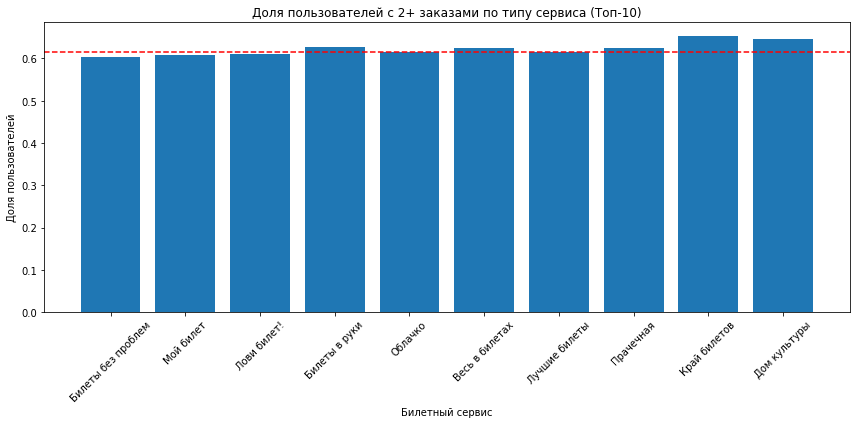

In [190]:
# Для визуализации построим столбчатую диаграмму для первой десятки билетных сервисов.

ratio_avg = by_first_service['ratio_2plus'].mean() # среднее значение для долей пользователей.

plt.figure(figsize=(12, 6))
plt.bar(by_first_service.head(10)['first_service'], by_first_service.head(10)['ratio_2plus'])
plt.axhline(ratio_avg, color='red', linestyle='--', label=f'Средняя доля: {ratio_avg:.2%}')
plt.title('Доля пользователей с 2+ заказами по типу сервиса (Топ-10)')
plt.xlabel('Билетный сервис')
plt.ylabel('Доля пользователей')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Доля пользователей,совершивших повторный заказ составляет примерно 60% для первой десятки лидеров продаж билетных сервисов.
Можно сделать вывод, что билетный сервис не влияет на желание покупателя сделать повторный заказ.

Вычислим долю пользователей, совершивших два и более заказа по жанрам.

In [191]:
by_first_genre = (
    user_profiles_filtered
    .groupby('first_genre')
    .agg(
        users_count=('user_id', 'count'),
        count_2plus =('is_two', 'sum')
    )
    .assign(ratio_2plus=lambda x: x['count_2plus'] / x['users_count'])
    .sort_values('users_count', ascending=False)
    .reset_index()
)

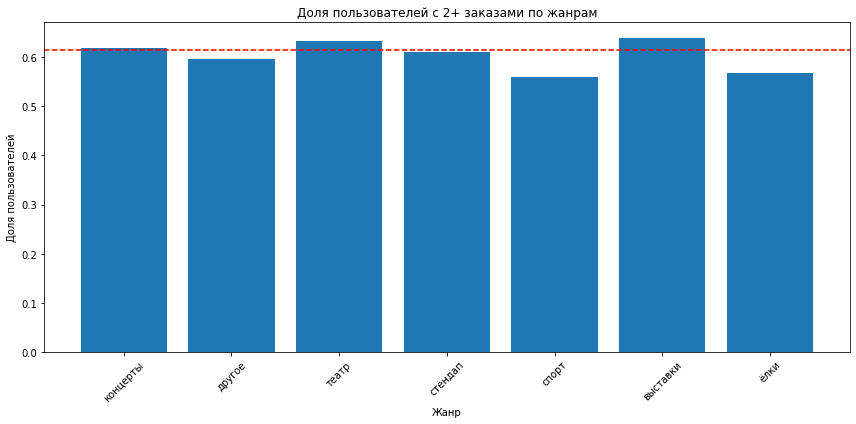

In [192]:
# Для визуализации построим столбчатую диаграмму.

ratio_avg = by_first_service['ratio_2plus'].mean() # среднее значение для долей пользователей.

plt.figure(figsize=(12, 6))
plt.bar(by_first_genre['first_genre'], by_first_genre['ratio_2plus'])
plt.axhline(ratio_avg, color='red', linestyle='--', label=f'Средняя доля: {ratio_avg:.2%}')
plt.title('Доля пользователей с 2+ заказами по жанрам')
plt.xlabel('Жанр')
plt.ylabel('Доля пользователей')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Расчитаем долю в зависимости от вида девайса, с которого сделан первый заказ

In [193]:
by_first_device = (
    user_profiles_filtered
    .groupby('first_device')
    .agg(
        users_count=('user_id', 'count'),
        count_2plus =('is_two', 'sum')
    )
    .assign(ratio_2plus=lambda x: x['count_2plus'] / x['users_count'])
    .sort_values('users_count', ascending=False)
    .reset_index()
)

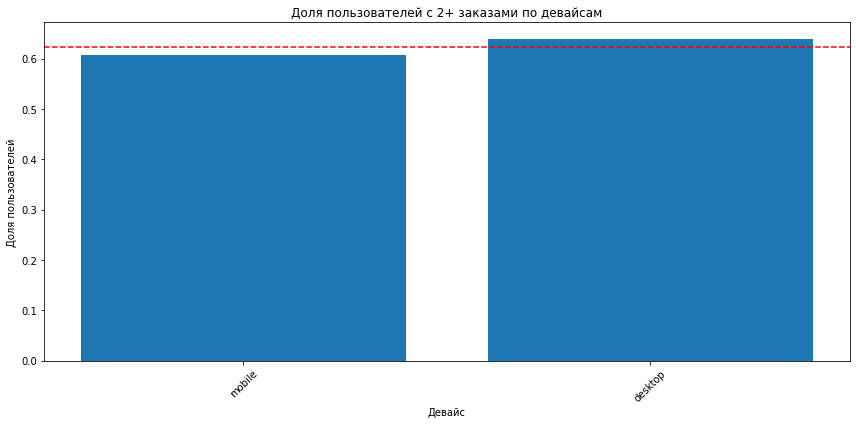

In [194]:
# Для визуализации построим столбчатую диаграмму.

ratio_avg = by_first_device['ratio_2plus'].mean() # среднее значение для долей пользователей.

plt.figure(figsize=(12, 6))
plt.bar(by_first_device['first_device'], by_first_device['ratio_2plus'])
plt.axhline(ratio_avg, color='red', linestyle='--', label=f'Средняя доля: {ratio_avg:.2%}')
plt.title('Доля пользователей с 2+ заказами по девайсам')
plt.xlabel('Девайс')
plt.ylabel('Доля пользователей')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Вычислим долю пользователей в зависимости от регионов первой покупки. Ограничимся первами 10 регионами лидерами по количеству пользователей.

In [195]:
by_first_region = (
    user_profiles_filtered
    .groupby('first_region')
    .agg(
        users_count=('user_id', 'count'),
        count_2plus =('is_two', 'sum')
    )
    .assign(ratio_2plus=lambda x: x['count_2plus'] / x['users_count'])
    .sort_values('users_count', ascending=False)
    .reset_index()
)

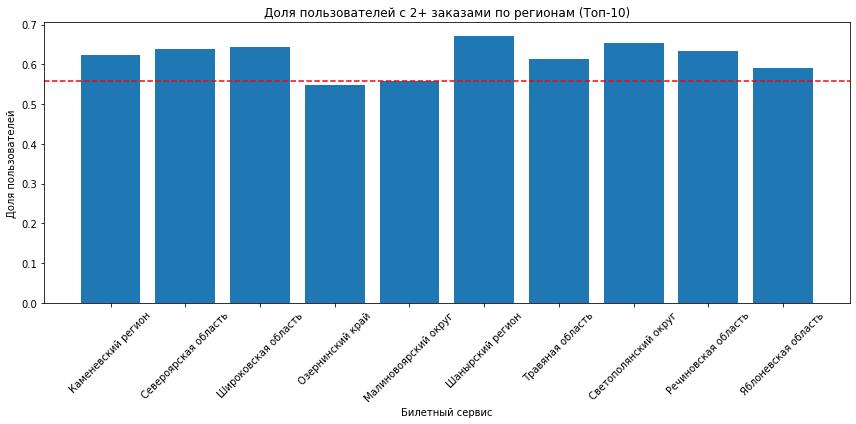

In [196]:
# Для визуализации построим столбчатую диаграмму для первой десятки регионов.

ratio_avg = by_first_region['ratio_2plus'].mean() # среднее значение для долей пользователей.

plt.figure(figsize=(12, 6))
plt.bar(by_first_region.head(10)['first_region'], by_first_region.head(10)['ratio_2plus'])
plt.axhline(ratio_avg, color='red', linestyle='--', label=f'Средняя доля: {ratio_avg:.2%}')
plt.title('Доля пользователей с 2+ заказами по регионам (Топ-10)')
plt.xlabel('Билетный сервис')
plt.ylabel('Доля пользователей')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Статистические расчеты и визуализации в виде столбчатых диграм выявили, что доля пользователей, совершивших повторный заказ составляет примерно 55-65% по всем показателям (жанры, регионы, девайсы и билетные сервисы).

Можно сделать вывод, что исследуемые метрики не имеют явного влияния на желание покупателя сделать повторный заказ.

---

**Задача 4.1.3.** Опираясь на выводы из задач выше, проверьте продуктовые гипотезы:

- **Гипотеза 1.** Тип мероприятия влияет на вероятность возврата на Яндекс Афишу: пользователи, которые совершили первый заказ на спортивные мероприятия, совершают повторный заказ чаще, чем пользователи, оформившие свой первый заказ на концерты.
- **Гипотеза 2.** В регионах, где больше всего пользователей посещают мероприятия, выше доля повторных заказов, чем в менее активных регионах.

---

Проверим гипотезу №1

In [197]:
by_first_genre = (
    user_profiles_filtered
    .groupby('first_genre')
    .agg(
        users_count=('user_id', 'count'),
        count_2plus =('is_two', 'sum')
    )
    .assign(ratio_2plus=lambda x: x['count_2plus'] / x['users_count'])
    .sort_values('users_count', ascending=False)
    .reset_index()
)
# Оставим только интеремующия нас жанры
by_first_genre_filtered = by_first_genre[by_first_genre['first_genre'].isin(['спорт', 'концерты'])] 

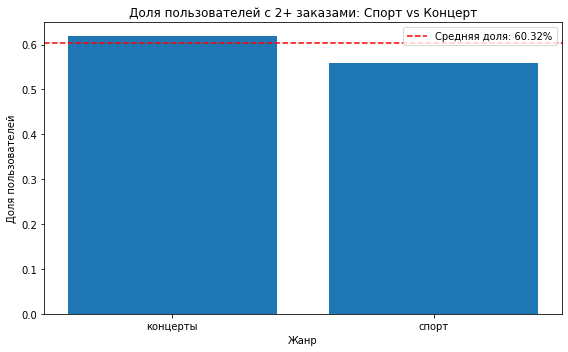

In [198]:
# Для визуализации построим столбчатую диаграмму с фильрацией по жанрам (только спорт и концерты)

genres_to_plot = ['спорт', 'концерты']
filtered = by_first_genre[by_first_genre['first_genre'].isin(genres_to_plot)]

ratio_avg = by_first_genre['ratio_2plus'].mean()

plt.figure(figsize=(8, 5))
plt.bar(filtered['first_genre'], filtered['ratio_2plus'])
plt.axhline(ratio_avg, color='red', linestyle='--', label=f'Средняя доля: {ratio_avg:.2%}')
plt.title('Доля пользователей с 2+ заказами: Спорт vs Концерт')
plt.xlabel('Жанр')
plt.ylabel('Доля пользователей')
plt.legend()
plt.tight_layout()
plt.show()



In [199]:
print(by_first_genre_filtered)


  first_genre  users_count  count_2plus  ratio_2plus
0    концерты         9561         5912     0.618345
4       спорт          797          446     0.559598


Доля пользователей, сделавших повторную покупку после посещения концертов равна 62% а после посещения спортивного мероприятия 56%. Следовательно гипотеза №1 не подтверждается.

Проверим гипотезу №2

In [200]:
# Выведем доли возвратившихся пользователей в активных и неактивных регеонах

ratio_avg_top20 = by_first_region.head(20)['ratio_2plus'].mean() # среднее значение для долей пользователей в активных регионах.
ratio_avg_tail20 = by_first_region.tail(20)['ratio_2plus'].mean() # среднее значение для долей пользователей в нетивных регионах.

print(f'Доля возвратившихся пользователей в активных регионах (топ‑20): {ratio_avg_top20:.2%}')
print(f'Доля возвратившихся пользователей в неактивных регионах (хвост‑20): {ratio_avg_tail20:.2%}')

Доля возвратившихся пользователей в активных регионах (топ‑20): 60.14%
Доля возвратившихся пользователей в неактивных регионах (хвост‑20): 47.22%


Гипотеза №2 подтверждается, так как в активных регионах доля возвратившихся пользоватедей составила 60% а неактивных 47%.

---

#### 4.2. Исследование поведения пользователей через показатели выручки и состава заказа

Изучите количественные характеристики заказов пользователей, чтобы узнать среднюю выручку сервиса с заказа и количество билетов, которое пользователи обычно покупают.

Эти метрики важны не только для оценки выручки, но и для оценки вовлечённости пользователей. Возможно, пользователи с более крупными и дорогими заказами более заинтересованы в сервисе и поэтому чаще возвращаются.

---

**Задача 4.2.1.** Проследите связь между средней выручкой сервиса с заказа и повторными заказами.

- Постройте сравнительные гистограммы распределения средней выручки с билета (`avg_revenue_rub`):
    - для пользователей, совершивших один заказ;
    - для вернувшихся пользователей, совершивших 2 и более заказа.
- Ответьте на вопросы:
    - В каких диапазонах средней выручки концентрируются пользователи из каждой группы?
    - Есть ли различия между группами?

Текст на сером фоне:
    
**Рекомендация:**

1. Используйте одинаковые интервалы (`bins`) и прозрачность (`alpha`), чтобы визуально сопоставить распределения.
2. Задайте параметру `density` значение `True`, чтобы сравнивать форму распределений, даже если число пользователей в группах отличается.

---


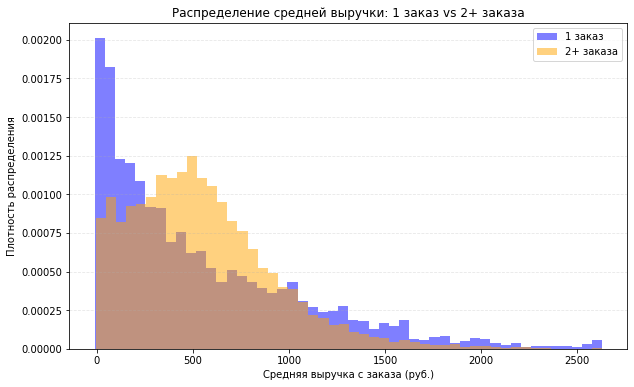

In [201]:
# Строим гистограмму распределения значений выручки по количеству купленных билетов

# Вначале распределим пользователей по 2-м группам

one_order = user_profiles_filtered[user_profiles_filtered['is_two'] == 0]['avg_revenue']
returned = user_profiles_filtered[user_profiles_filtered['is_two'] == 1]['avg_revenue']


# Построение гистограмм с одинаковыми бинами и плотностью
bins = 50  # количество интервалов
plt.figure(figsize=(10, 6))
plt.hist(one_order, bins=bins, density=True, alpha=0.5, label='1 заказ', color='blue')
plt.hist(returned, bins=bins, density=True, alpha=0.5, label='2+ заказа', color='orange')

plt.title('Распределение средней выручки: 1 заказ vs 2+ заказа')
plt.xlabel('Средняя выручка с заказа (руб.)')
plt.ylabel('Плотность распределения')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show() 

И гистограммы видно, что пользователи, совершившие один заказ сконцентрированы в диапазоне средней выручки близким к минимальным значениям, далее их концентрация снижается с увеличением средней выручки

Группа пользователей, совершивших 2 и более покупки сконцентрирована окола значения 500 рублей. Распределение таких пользователей напоминает нормальное.


---

**Задача 4.2.2.** Сравните распределение по средней выручке с заказа в двух группах пользователей:

- совершившие 2–4 заказа;
- совершившие 5 и более заказов.

Ответьте на вопрос: есть ли различия по значению средней выручки с заказа между пользователями этих двух групп?

---


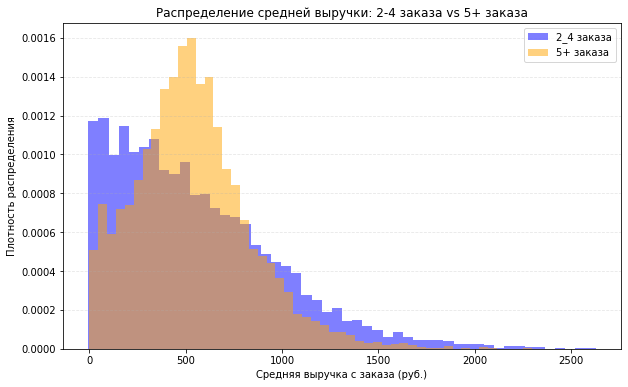

In [202]:
# Строим гистограмму распределения значений выручки по количеству купленных билетов

# Вначале распределим пользователей по 2-м группам

order_2_4 = user_profiles_filtered[(user_profiles_filtered['is_five'] == 0) & 
                                   (user_profiles_filtered['is_two'] == 1)]['avg_revenue']
order_5 = user_profiles_filtered[user_profiles_filtered['is_five'] == 1]['avg_revenue']

# Построение гистограмм с одинаковыми бинами и плотностью
bins = 50  # количество интервалов
plt.figure(figsize=(10, 6))
plt.hist(order_2_4, bins=bins, density=True, alpha=0.5, label='2_4 заказа', color='blue')
plt.hist(order_5, bins=bins, density=True, alpha=0.5, label='5+ заказа', color='orange')

plt.title('Распределение средней выручки: 2-4 заказа vs 5+ заказа')
plt.xlabel('Средняя выручка с заказа (руб.)')
plt.ylabel('Плотность распределения')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.3)
plt.show() 

In [203]:
# посчитаем среднее значение выручки для обеих групп

avg_rev_2_4 = user_profiles_filtered[
    (user_profiles_filtered['is_five'] == 0) & 
    (user_profiles_filtered['is_two'] == 1)
]['avg_revenue'].mean()

avg_rev_5 = user_profiles_filtered[user_profiles_filtered['is_five'] == 1]['avg_revenue'].mean()

print(f'Средняя выручка для 2–4 заказов: {avg_rev_2_4:.2f}') 
print(f'Средняя выручка для 5 и более заказов: {avg_rev_5:.2f}') 

Средняя выручка для 2–4 заказов: 551.57
Средняя выручка для 5 и более заказов: 535.89



Между двумя рассматриваемфми группами есть небольшая разница по средним значениям выручки в пользу группы пользователей от 2-х до 4-х заказов.

---

**Задача 4.2.3.** Проанализируйте влияние среднего количества билетов в заказе на вероятность повторной покупки.

- Изучите распределение пользователей по среднему количеству билетов в заказе (`avg_tickets_count`) и опишите основные наблюдения.
- Разделите пользователей на несколько сегментов по среднему количеству билетов в заказе:
    - от 1 до 2 билетов;
    - от 2 до 3 билетов;
    - от 3 до 5 билетов;
    - от 5 и более билетов.
- Для каждого сегмента подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы.
- Ответьте на вопросы:
    - Как распределены пользователи по сегментам — равномерно или сконцентрировано?
    - Есть ли сегменты с аномально высокой или низкой долей повторных покупок?

---

In [204]:
# Изучим столбец с средним количеством билетов
print(user_profiles_filtered['avg_tickets'].describe())


count    21638.000000
mean         2.743319
std          0.917486
min          1.000000
25%          2.000000
50%          2.750000
75%          3.095238
max         11.000000
Name: avg_tickets, dtype: float64


В среднем плльзователи покупают по 2.74 билета за заказ. Медиана выборки очень близка к среднему значению. Но максимальное значение в 11 раз отличается от минимального, возможно покупатель учебное заведение.

In [205]:
# Визуализируем столбец 'avg_tickets' в виде гистограммы

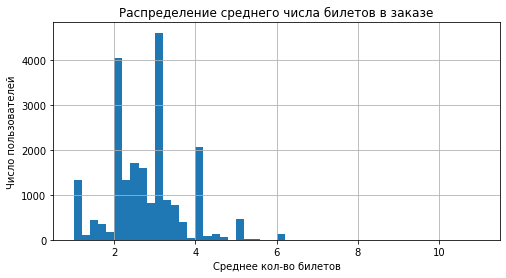

In [206]:
user_profiles_filtered['avg_tickets'].hist(bins=50, figsize=(8, 4))
plt.title('Распределение среднего числа билетов в заказе')
plt.xlabel('Среднее кол-во билетов')
plt.ylabel('Число пользователей')
plt.show()


In [207]:
# Сделаем сегментацию и агрегацию по сегментам:

In [208]:
# Сегментация
def assign_ticket_segment(x):
    if 1 <= x < 2:
        return '1–2 билета'
    elif 2 <= x < 3:
        return '2–3 билета'
    elif 3 <= x < 5:
        return '3–5 билетов'
    elif x >= 5:
        return '5+ билетов'
    else:
        return 'Другое'

user_profiles_filtered['ticket_segment'] = user_profiles_filtered['avg_tickets'].apply(assign_ticket_segment)

# Агрегация по сегментам
segments = user_profiles_filtered.groupby('ticket_segment').agg(
        users_count=('user_id', 'count'),
        returned_count=('is_two', 'sum')) 

#  Добавим столбец с долей вернувшихся покупателей.

segments['return_ratio'] = segments['returned_count'] / segments['users_count']

print(segments)

                users_count  returned_count  return_ratio
ticket_segment                                           
1–2 билета             2419            1241      0.513022
2–3 билета             9498            6989      0.735839
3–5 билетов            9060            4916      0.542605
5+ билетов              661             124      0.187595


/tmp/ipykernel_35/4263441394.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  user_profiles_filtered['ticket_segment'] = user_profiles_filtered['avg_tickets'].apply(assign_ticket_segment)


Большинство пользователей сконцентрировано в сегментах 2-3 и 3-5 билетов - 9.5 и 9.0 тысячь соответсвенно.
Количество тех, кто покупал 1-2 билета 2.4 тысячи. Меньше всего покупателей - 660 человек в сегменте 5 и более билетов.

Лидер возвратившихся покупателей сегмент 2-3 билета - возвратилось почти 74 % пользователей
51 и 54 % возвратившихся в сегментах 1-2 и 3-5 соответсвенно

Меньше всего возвращались к покупкам те пользователи, которые покупали 5 и более билетов, их доля составила 19 %.

---

#### 4.3. Исследование временных характеристик первого заказа и их влияния на повторные покупки

Изучите временные параметры, связанные с первым заказом пользователей:

- день недели первой покупки;
- время с момента первой покупки — лайфтайм;
- средний интервал между покупками пользователей с повторными заказами.

---

**Задача 4.3.1.** Проанализируйте, как день недели, в которой была совершена первая покупка, влияет на поведение пользователей.

- По данным даты первого заказа выделите день недели.
- Для каждого дня недели подсчитайте общее число пользователей и долю пользователей, совершивших повторные заказы. Результаты визуализируйте.
- Ответьте на вопрос: влияет ли день недели, в которую совершена первая покупка, на вероятность возврата клиента?

---


Извлекем день недели первой покупки

In [209]:
# используем метод .day_name()

user_profiles_filtered['first_weekday'] = user_profiles_filtered['first_order_date'].dt.day_name()

/tmp/ipykernel_35/1324498371.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  user_profiles_filtered['first_weekday'] = user_profiles_filtered['first_order_date'].dt.day_name()


Делаем агрегацию количество полбзователей по дням недели

In [210]:
weekdays = user_profiles_filtered.groupby('first_weekday').agg(users_count=('user_id', 'count'), 
                                                               returned_count=('is_two', 'sum')).reset_index()
    
   

Добавим долю вернувшихся

In [211]:
weekdays['return_ratio'] = weekdays['returned_count'] / weekdays['users_count']
print(weekdays)

  first_weekday  users_count  returned_count  return_ratio
0        Friday         3259            1950      0.598343
1        Monday         2930            1847      0.630375
2      Saturday         3326            2089      0.628082
3        Sunday         2777            1667      0.600288
4      Thursday         3113            1850      0.594282
5       Tuesday         3176            1966      0.619018
6     Wednesday         3057            1901      0.621851


Для наглядности визуализируем долю вернувшихся пользователей

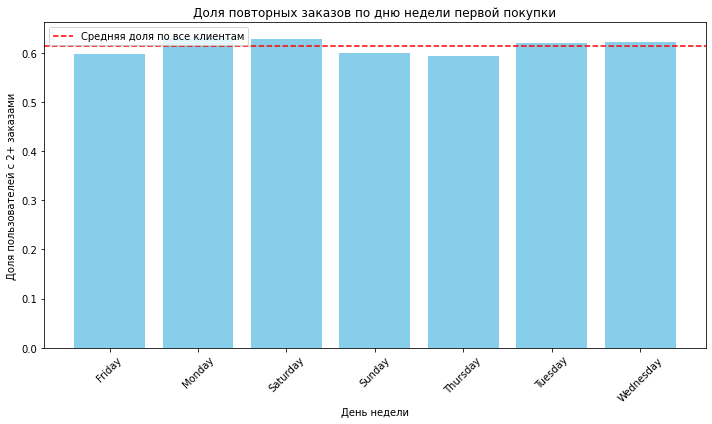

In [212]:
plt.figure(figsize=(10, 6))
plt.bar(weekdays['first_weekday'], weekdays['return_ratio'], color='skyblue')
plt.axhline(user_profiles_filtered['is_two'].mean(), color='red', linestyle='--', label='Средняя доля по все клиентам')
plt.title('Доля повторных заказов по дню недели первой покупки')
plt.xlabel('День недели')
plt.ylabel('Доля пользователей с 2+ заказами')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

Доля вернувшихсф пользователей по дням недели колеблется в пределах среднего значения по выборке. 

Максимальная доля вернувшихся оказалась в понедельник - 63 %

Минимальная доля вернувшихся в четверг - 59.4 %

Дни недели не имеют явного влияния на решение покупателей сделать повторную покупку.

---

**Задача 4.3.2.** Изучите, как средний интервал между заказами влияет на удержание клиентов.

- Рассчитайте среднее время между заказами для двух групп пользователей:
    - совершившие 2–4 заказа;
    - совершившие 5 и более заказов.
- Исследуйте, как средний интервал между заказами влияет на вероятность повторного заказа, и сделайте выводы.

---


Разделим пользователей на соответсвующие группы и посчитаем для каждой из них средний интервал между заказами 

In [213]:

avg_interval_2_4 = user_profiles_filtered[
    (user_profiles_filtered['is_five'] == 0) & 
    (user_profiles_filtered['is_two'] == 1)
]['avg_time_between_orders_sec'].mean() / 86400

avg_interval_5 = user_profiles_filtered[user_profiles_filtered['is_five'] == 1]['avg_time_between_orders_sec'].mean() / 86400

print(f'Средний интервал между покупками для 2–4 заказов: {avg_interval_2_4:.2f}') 
print(f'Средний интервал между покупками для 5 и более заказов: {avg_interval_5:.2f}') 

Средний интервал между покупками для 2–4 заказов: 21.41
Средний интервал между покупками для 5 и более заказов: 9.97


Пользователи, совершившие 5 и более заказов, следующую покупку делали в 2 раза быстрее - через 10 дней, чем пользователи, совершившие 2-4 заказа, которые возвращались к покупке через 21 день.

---

#### 4.4. Корреляционный анализ количества покупок и признаков пользователя

Изучите, какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок. Для этого используйте универсальный коэффициент корреляции `phi_k`, который позволяет анализировать как числовые, так и категориальные признаки.

---

**Задача 4.4.1:** Проведите корреляционный анализ:
- Рассчитайте коэффициент корреляции `phi_k` между признаками профиля пользователя и числом заказов (`total_orders`). При необходимости используйте параметр `interval_cols` для определения интервальных данных.
- Проанализируйте полученные результаты. Если полученные значения будут близки к нулю, проверьте разброс данных в `total_orders`. Такое возможно, когда в данных преобладает одно значение: в таком случае корреляционный анализ может показать отсутствие связей. Чтобы этого избежать, выделите сегменты пользователей по полю `total_orders`, а затем повторите корреляционный анализ. Выделите такие сегменты:
    - 1 заказ;
    - от 2 до 4 заказов;
    - от 5 и выше.
- Визуализируйте результат корреляции с помощью тепловой карты.
- Ответьте на вопрос: какие признаки наиболее связаны с количеством заказов?

---

Для вычисления корреляционной матрицы, исключим даты, а так же столбцы 'is_two' и 'is_five', так как они также содержать количиство заказоа как и сам столбец 'orders_count'

In [214]:
# Вычисляем корреляционную матрицу с использованием phi_k
correlation_matrix = user_profiles_filtered[['first_device',
       'first_region', 'first_service', 'first_genre', 'orders_count',
       'avg_revenue', 'avg_tickets', 'avg_time_between_orders_sec', 
       'ticket_segment', 'first_weekday']].phik_matrix()

# Выводим результат, оставим только интересующий столбец 'orders_count'
print('Корреляционная матрица с коэффициентом phi_k для переменной orders_count')
correlation_matrix.loc[correlation_matrix.index != 'orders_count'][['orders_count']].sort_values(by='orders_count', ascending=False)

interval columns not set, guessing: ['orders_count', 'avg_revenue', 'avg_tickets', 'avg_time_between_orders_sec']
Корреляционная матрица с коэффициентом phi_k для переменной orders_count


,orders_count
avg_time_between_orders_sec,0.285684
avg_tickets,0.225904
avg_revenue,0.219482
ticket_segment,0.202643
first_region,0.113139
first_weekday,0.060831
first_service,0.034971
first_genre,0.025236
first_device,0.024306


Для более точного расчета, разделим данные на числовые и гатегориальные

Корреляционная матрица с коэффициентом phi_k для переменной order_count


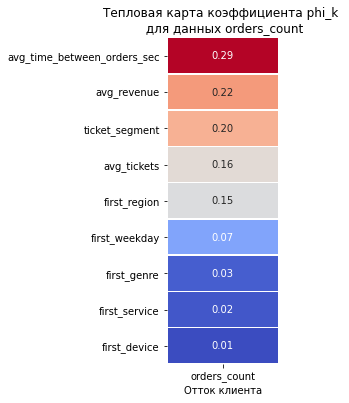

In [215]:
# Числовые данные:
cols_interval = ['orders_count', 'avg_revenue', 'avg_tickets', 'avg_time_between_orders_sec']

# Категориальные данные:
cols_categorical = ['first_device', 'first_region', 'first_service', 'first_genre', 'ticket_segment', 'first_weekday']

# Создаем новый датасет для корреляционного анализа без пропусков:
df_selected = user_profiles_filtered[cols_interval + cols_categorical].dropna()


# interval_cols указывает, какие колонки считать числами, остальные — категориями
corr_matrix = df_selected.phik_matrix(interval_cols=cols_interval)
print('Корреляционная матрица с коэффициентом phi_k для переменной order_count')
corr_matrix.loc[corr_matrix.index != 'orders_count'][['orders_count']].sort_values(by='orders_count', ascending=False)


# Строим тепловую карту
plt.figure(figsize=(2, 6))

# Сохраняем матрицу корреляции признака order_count с другими признаками клиента
data_heatmap = corr_matrix.loc[corr_matrix.index != 'orders_count'][['orders_count']].sort_values(by='orders_count', ascending=False)
sns.heatmap(data_heatmap,
            annot=True, # Отображаем численные значения в ячейках карты
            fmt='.2f', # Форматируем значения корреляции: два знака после точки
            cmap='coolwarm', # Устанавливаем цветовую гамму от красного (макс. значение) к синему
            linewidths=0.5, # Форматируем линию между ячейками карты
            cbar=False # Отключаем цветовую шкалу
           )

# Добавляем заголовок и подпись по оси Х
plt.title('Тепловая карта коэффициента phi_k \n для данных orders_count')
plt.xlabel('Отток клиента')

# Выводим график
plt.show()

По резулбтатам корреляционнй матрицы, видно, что ниболшее влияние на количество заказов имеет среднее время между заказами 0.29. Роложительный коэффициент говорит о том, что, чем больше среднее время между заказами, тем больше их количество.

С коэффициентом 0.22 имеет влтяние средняя выручка с клиента.

С коэффициентом 0.20 имеет влияние билетный сегмент клиента. Здесь необходимо отметить положительный коэффициент 0.16 для среднего количества купленных билетов за заказ, что говорит о прямой зависимости колочиства заказов от от количества купленых билетов за один заказ.

Коэффициент регионов 0.15, для его оценки необходимо построить столбцатую диаграмму.

In [216]:
# Проверка: сколько уникальных значений и какое модальное?
print(df_selected['orders_count'].value_counts().head(15))

2     3572
3     2175
4     1400
5      971
6      700
7      542
8      455
9      384
10     291
11     231
12     198
13     155
14     154
16     136
15     124
Name: orders_count, dtype: int64


В расчитанной кореляционной матрице не учтены данные только с одним заказом, так как столбец 'avg_time_between_orders_sec' выдаст Nan, которые исключаются из расчета корреляционных коэффициентов. Уберем столбец 'avg_time_between_orders_sec' и пересчитаем матрицу

In [217]:
# Вычисляем корреляционную матрицу с использованием phi_k
correlation_matrix = user_profiles_filtered[['first_device',
       'first_region', 'first_service', 'first_genre', 'orders_count',
       'avg_revenue', 'avg_tickets', 
       'ticket_segment', 'first_weekday']].phik_matrix()

# Выводим результат, оставим только интересующий столбец 'orders_count'
print('Корреляционная матрица с коэффициентом phi_k для переменной orders_count')
correlation_matrix.loc[correlation_matrix.index != 'orders_count'][['orders_count']].sort_values(by='orders_count', ascending=False)

interval columns not set, guessing: ['orders_count', 'avg_revenue', 'avg_tickets']
Корреляционная матрица с коэффициентом phi_k для переменной orders_count


,orders_count
avg_tickets,0.225904
avg_revenue,0.219482
ticket_segment,0.202643
first_region,0.113139
first_weekday,0.060831
first_service,0.034971
first_genre,0.025236
first_device,0.024306


При учете еденичных заказов видим, что количество купленных билетов имеет болшее влияние (0.22 против 0.16 без учета). Это говорит о том, что при единичном заказе, покупалось большее количетво билетов.

### 5. Общий вывод и рекомендации

В конце проекта напишите общий вывод и рекомендации: расскажите заказчику, на что нужно обратить внимание. В выводах кратко укажите:

- **Информацию о данных**, с которыми вы работали, и то, как они были подготовлены: например, расскажите о фильтрации данных, переводе тенге в рубли, фильтрации выбросов.
- **Основные результаты анализа.** Например, укажите:
    - Сколько пользователей в выборке? Как распределены пользователи по числу заказов? Какие ещё статистические показатели вы подсчитали важным во время изучения данных?
    - Какие признаки первого заказа связаны с возвратом пользователей?
    - Как связаны средняя выручка и количество билетов в заказе с вероятностью повторных покупок?
    - Какие временные характеристики влияют на удержание (день недели, интервалы между покупками)?
    - Какие характеристики первого заказа и профиля пользователя могут быть связаны с числом покупок согласно результатам корреляционного анализа?
- Дополните выводы информацией, которая покажется вам важной и интересной. Следите за общим объёмом выводов — они должны быть компактными и ёмкими.

В конце предложите заказчику рекомендации о том, как именно действовать в его ситуации. Например, укажите, на какие сегменты пользователей стоит обратить внимание в первую очередь, а какие нуждаются в дополнительных маркетинговых усилиях.

**Выводы**

Первоначальный датасет содержал 290611 записей. В колонке с выручкой имелись данные с валютой казахстанский тенге, которая была приведена к общей валюте рубли и выделена новая колонка revenue_rub.

После анализа статистических данных, в колонке revenue_rub были выявлены выбросы. После фильтрации выбросов в дата сете осталось 287786 строк (удалили 9.5% данных)

После группировки датасета по пользователям, выявлено 21853 уникальных пользователя. В столюце с количеством заказов для каждого пользователя были выявлены выбросы. После фильтрации было исключено 216 пользователей, что составляет 0.1 % от общего числа. Незначительный процент выбросов позволяет их не учитывать при анализе.
В итоговом датасете всего осталось пользователей: 21638, средний чек: 544.71 рублей, доля пользователей с 2+ заказами: 61.33%, доля пользователей с 5+ заказами: 28.30%

Большинство пользователей сконцентрировано в сегментах 2-3 и 3-5 билетов - 9.5 и 9.0 тысячь соответсвенно. Количество тех, кто покупал 1-2 билета 2.4 тысячи. Меньше всего покупателей - 660 человек в сегменте 5 и более билетов.

Лидер возвратившихся покупателей сегмент 2-3 билета - возвратилось почти 74 % пользователей 51 и 54 % возвратившихся в сегментах 1-2 и 3-5 соответсвенно

Меньше всего возвращались к покупкам те пользователи, которые покупали 5 и более билетов, их доля составила 19 %.

Корреляционный анализ показал очевидный результат - более активные клиенты (с большей выручкой и большим количеством билетов) совершали больше заказов.

**Реккомендации**

Результаты исследовательского анализа позволяют принять следующие рекомендации:
Поощреять клиентов, делающих заказы в пределах 2-3 билетов - это основная масса клиентов, которые совершают повторные покупки, их стоит максимально удерживать.

Очень небольшой процент возратившихся клиентов, сделавших заказ с 5 и более билетами. Если это учебные заведения, то стоит обратить внимание на рекламу мероприятий в этих заведениях. Если это перекупы, так же стоит принять соответствующие меры.

### 6. Финализация проекта и публикация в Git

Когда вы закончите анализировать данные, оформите проект, а затем опубликуйте его.

Выполните следующие действия:

1. Создайте файл `.gitignore`. Добавьте в него все временные и чувствительные файлы, которые не должны попасть в репозиторий.
2. Сформируйте файл `requirements.txt`. Зафиксируйте все библиотеки, которые вы использовали в проекте.
3. Вынести все чувствительные данные (параметры подключения к базе) в `.env`файл.
4. Проверьте, что проект запускается и воспроизводим.
5. Загрузите проект в публичный репозиторий — например, на GitHub. Убедитесь, что все нужные файлы находятся в репозитории, исключая те, что в `.gitignore`. Ссылка на репозиторий понадобится для отправки проекта на проверку. Вставьте её в шаблон проекта в тетрадке Jupyter Notebook перед отправкой проекта на ревью.

**Вставьте ссылку на проект в этой ячейке тетрадки перед отправкой проекта на ревью.**